## **X10**: TT - Tree Classifiers and the Number of Folds
* October 21°, 2026
#### ESCOM - IPN:

#### *B.S. in Computer Science*
> Miguel Alexander Sanchez Garcia

#### **0° Introduction**

At the review of October 21, a member of the jury asked two things (D-043):

1. **Why five folds?** D-018 adopted five without stating a reason, and the reviewer found it too many.
2. **Tree classifiers.** Looking at the t-SNE of Module 6, the reviewer suggested decision trees and XGBoost: they model non-linear interactions, and that is where C4 and C5 could do better. The reviewer asked to document how the tree is stopped, by depth or by node purity, and to explain *why* if the trees do better.

This notebook is exploratory and does not change the design. It follows the pattern of X4–X6 (D-038): the same search for every representation, nested cross-validation with the frozen folds of M4, and one evaluation per model on the official test split.

**The question, fixed before running.** With the **same classifier**, does C4 or C5 beat C1? The comparisons are C4−C1, C5−C1, C4−C3, C5−C3, C2−C1 and C5−C4 within each classifier. A tree on C4 against the MLP on C1 changes two things at once and is not read as an advantage.

**A bound known in advance.** C4 and C5 are deterministic functions of the angle vector $x$ of C1: $\langle Z_i\rangle = f_i(x)$. The chain $Y \to x \to f(x)$ and the data processing inequality give $I(Y; f(x)) \le I(Y; x)$: no classifier can extract from $f(x)$ information about the label that $x$ did not contain. The best possible classifier on C4 is never better than the best possible one on C1. A finite-sample advantage can still come from the **inductive bias** of a particular classifier: $f$ may present the information in a shape that suits it.

**Why trees are a different test from the MLP.** Both are non-linear and both can model interactions. They differ in their inductive bias:
- **A tree** cuts one axis at a time and predicts a constant per region. It is invariant to any monotone rescaling of each feature, but **not** to a rotation.
- **An MLP** builds smooth functions, and its first layer absorbs any linear transformation of the input.

Two consequences follow. **C2 stops being a null control for trees**: C2 is a rotation of C1 (a full PCA), which the MLP sees as the same input and a tree does not. And the quantile scaling of M4 is irrelevant to a tree.

#### **0°a The protocol (D-043)**

| Element | Choice | Why |
|---|---|---|
| Inputs | The five representations of Module 5, k = 12 | The same vectors as Module 7 |
| Decision tree, pre-pruning by depth (DT-depth) | `max_depth` 1 to 12 | The first stopping rule the reviewer named |
| Decision tree, pre-pruning by purity (DT-purity) | Stop at the first node of the path whose majority-class share is at least p, with p from 0.55 to 1.00 | The second rule the reviewer named. scikit-learn removed `min_impurity_split`, so the rule is applied on the grown tree |
| Decision tree, cost-complexity post-pruning (DT-ccp) | `ccp_alpha` from 0 to 0.02 | The textbook rule (CART): grow the full tree, then prune |
| Random forest (RF) | 500 trees; `max_features` × `min_samples_leaf` | Averages many deep trees to cut the variance of one tree |
| Gradient boosting (XGB) | XGBoost; `max_depth` × `learning_rate` × `n_estimators` | Adds shallow trees in sequence, each one correcting the previous ones |
| Class imbalance | Balanced class weights, $w_c = N/(C N_c)$ | The same weights as the MLP of Module 7 |
| Hyperparameters | Nested cross-validation: outer = the 5 frozen folds of M4; inner = 3 folds grouped by patient; ties go to the simplest option | The same search for the five representations; the outer fold never chooses anything |
| Test | One fit on the whole training split, evaluated once; 2,000 patient-bootstrap resamples, paired | As in Module 7 |
| Why the trees win or lose | Training and validation curves for each stopping rule; XGB without interactions; permutation importance; the rules of a depth-3 tree | Each tool answers a different "why" |
| Number of folds | The MLP of Module 7 with 3 folds grouped by patient | The reviewer's question, answered with data |

#### **1° Setup**

**a.** Libraries, parameters and determinism. With `X10_QUICK=1` the notebook runs with reduced grids and writes to `/tmp/x10_quick`, as a smoke test.

In [1]:
import copy
import json
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import xgboost
from matplotlib.lines import Line2D
from scipy.stats import rankdata
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)
QUICK = os.environ.get('X10_QUICK') == '1'
SEED, N_FOLDS, N_INNER, K = 42, 5, 3, 12
N_BOOT = 50 if QUICK else 2000
N_PERM = 2 if QUICK else 10
N_TREES = 50 if QUICK else 500
N_SEED_CANDIDATES = 5 if QUICK else 200
FINDINGS = ['mass', 'calcification']
TITLES = {'mass': 'Masses', 'calcification': 'Calcifications'}
CONDITIONS = ['C1', 'C2', 'C3', 'C4', 'C5']
GRIDS = {                                                   # each grid runs from the simplest option to the most complex
    'DT-depth': [{'max_depth': d} for d in range(1, 13)],
    'DT-purity': [{'purity': p} for p in np.round(np.arange(0.55, 1.0001, 0.05), 2)],
    'DT-ccp': [{'ccp_alpha': a} for a in [2e-2, 1e-2, 5e-3, 2e-3, 1e-3, 3e-4, 1e-4, 0.0]],
    'RF': [{'min_samples_leaf': leaf, 'max_features': mf} for leaf in [20, 5, 1] for mf in ['sqrt', 0.5, 1.0]],
    'XGB': [{'n_estimators': n, 'learning_rate': lr, 'max_depth': d} for n in [100, 300] for lr in [0.03, 0.1] for d in [2, 3, 4, 6]],
}
GRIDS['XGB-additive'] = GRIDS['XGB']
if QUICK:
    GRIDS = {f: g[:2] + g[-1:] for f, g in GRIDS.items()}
FAMILIES = ['DT-depth', 'DT-purity', 'DT-ccp', 'RF', 'XGB']      # evaluated on test
STOP_PARAM = {'DT-depth': 'max_depth', 'DT-purity': 'purity', 'DT-ccp': 'ccp_alpha'}
# M7 MLP, copied from 7_Classification (D-036), for the fold sensitivity
BATCH, MAX_EPOCHS, PATIENCE, INNER_VAL = 128, 400, 40, 0.15
MLP_CONFIG = dict(hidden=(32, 16), lr=1e-3, weight_decay=1e-4, standardize=True)
ROOT = Path('/Users/alexander_san/TT')
M4_DIR, M5_DIR, M7_DIR = ROOT / 'Data/processed/m4', ROOT / 'Data/processed/m5', ROOT / 'Data/processed/m7'
if QUICK:
    RESULTS_DIR = FIG_DIR = OUT_DIR = Path('/tmp/x10_quick')
else:
    RESULTS_DIR, FIG_DIR, OUT_DIR = ROOT / 'Code/results', ROOT / 'Docs/Figures', ROOT / 'Data/processed/x10'
for p in {RESULTS_DIR, FIG_DIR, OUT_DIR}:
    p.mkdir(parents=True, exist_ok=True)
LOG = Path('/tmp/x10_run.log')
COLORS = {'C1': '#eda100', 'C2': '#e87ba4', 'C3': '#2a78d6', 'C4': '#eb6834', 'C5': '#1baf7a'}
INK = '#3d3d3a'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'lines.markersize': 8})


def log(msg):
    # progress also goes to a file, because nbconvert shows nothing until the end
    line = f"{time.strftime('%H:%M:%S')} {msg}"
    print(line, flush=True)
    with LOG.open('a') as fh:
        fh.write(line + '\n')


log(f"X10 start (QUICK={QUICK}) | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | torch {torch.__version__} | numpy {np.__version__}")

10:17:24 X10 start (QUICK=False) | scikit-learn 1.7.2 | xgboost 3.2.0 | torch 2.10.0 | numpy 2.2.6


**b.** Load the representations of Module 5 and check them against the frozen folds and the angle vectors of Module 4

In [2]:
checks = []


def check(name, value, passed):
    checks.append({'check': name, 'value': float(value), 'passed': bool(passed)})


cols = lambda c, k=K: [f'{c}_{j:02d}' for j in range(1, k + 1)]
short = lambda name: name.replace('original_', '').replace('firstorder_', 'fo_').replace('shape2D_', 'sh_')
data = {}
for ft in FINDINGS:
    emb = pd.read_parquet(M5_DIR / f'emb_{ft}.parquet').reset_index(drop=True)
    m4 = pd.read_parquet(M4_DIR / f'x_{ft}.parquet').set_index('case_id').loc[emb.case_id]
    feats = json.loads((M4_DIR / f'x_{ft}.json').read_text())['features']
    check(f'{ft}: Module 5 folds equal the frozen folds of M4', 0, (m4.fold.to_numpy() == emb.fold.to_numpy()).all())
    err = np.abs(m4[[f'x_{j:02d}' for j in range(1, K + 1)]].to_numpy() - emb[cols('C1')].to_numpy()).max()
    check(f'{ft}: C1 is the angle vector of M4', err, err < 1e-12)
    tr, te = emb.split.eq('train').to_numpy(), emb.split.eq('test').to_numpy()
    split_patients = int((emb[tr].groupby('patient_id').fold.nunique() > 1).sum())
    check(f'{ft}: no patient has lesions in two folds', split_patients, split_patients == 0)
    data[ft] = {'frame': emb, 'y': emb.label.to_numpy(int), 'folds': emb.fold.to_numpy(int), 'groups': emb.patient_id.to_numpy(),
                'tr': tr, 'te': te, 'X': {c: emb[cols(c)].to_numpy(float) for c in CONDITIONS}, 'features': [short(f) for f in feats]}
    log(f"{ft:13s}: train {tr.sum()} lesions ({data[ft]['y'][tr].sum()} malignant) | test {te.sum()} lesions")
display(pd.DataFrame(checks))

10:17:24 mass         : train 1318 lesions (637 malignant) | test 378 lesions


10:17:24 calcification: train 1546 lesions (544 malignant) | test 326 lesions


,check,value,passed
0,mass: Module 5 folds equal the frozen folds of M4,0.0,True
1,mass: C1 is the angle vector of M4,0.0,True
2,mass: no patient has lesions in two folds,0.0,True
3,calcification: Module 5 folds equal the frozen...,0.0,True
4,calcification: C1 is the angle vector of M4,0.0,True
5,calcification: no patient has lesions in two f...,0.0,True


**c.** Inner splits for the nested search: 3 folds grouped by patient inside the training part of each outer fold, and inside the whole training split for the final model. They are computed once and shared by every representation and classifier, so all of them are tuned on the same partitions.

In [3]:
def inner_splits(idx, y, groups):
    sgkf = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=SEED)
    return [(idx[i], idx[j]) for i, j in sgkf.split(idx, y[idx], groups[idx])]


for ft in FINDINGS:
    d = data[ft]
    d['inner'] = {f: inner_splits(np.flatnonzero(d['tr'] & (d['folds'] != f)), d['y'], d['groups']) for f in range(N_FOLDS)}
    d['inner']['all'] = inner_splits(np.flatnonzero(d['tr']), d['y'], d['groups'])
    leak = sum(len(set(d['groups'][a]) & set(d['groups'][b])) for splits in d['inner'].values() for a, b in splits)
    check(f'{ft}: no patient on both sides of an inner split', leak, leak == 0)
    outer_in_inner = sum(np.isin(np.concatenate([a for a, _ in d['inner'][f]]), np.flatnonzero(d['folds'] == f)).sum() for f in range(N_FOLDS))
    check(f'{ft}: the outer validation fold never enters its inner search', outer_in_inner, outer_in_inner == 0)
    test_in_search = sum(d['te'][np.concatenate([a for a, _ in s])].sum() for s in d['inner'].values())
    check(f'{ft}: the test split never enters any search', test_in_search, test_in_search == 0)
display(pd.DataFrame(checks).tail(6))

,check,value,passed
6,mass: no patient on both sides of an inner split,0.0,True
7,mass: the outer validation fold never enters i...,0.0,True
8,mass: the test split never enters any search,0.0,True
9,calcification: no patient on both sides of an ...,0.0,True
10,calcification: the outer validation fold never...,0.0,True
11,calcification: the test split never enters any...,0.0,True


#### **2° The classifiers**

**a.** Models, the purity rule and the nested search

**How the purity rule works.** A tree is grown in full. Each node stores the class shares of the training lesions that reach it, weighted with the balanced class weights, so the root has 50 % of each class. To predict a lesion, it walks from the root towards its leaf and **stops at the first node whose majority class reaches the share p**; the prediction is the malignant share of that node. With p = 1.00 the walk always ends at the leaf, which is the full tree. The lower p, the earlier the tree stops and the simpler it is.

**The three ways to stop a tree.**
- **Depth** limits how many questions a tree can ask.
- **Purity** stops asking once a region is clean enough.
- **Cost-complexity** grows everything and then removes the branches whose gain in purity does not pay for the leaves they add (a penalty α per leaf).

The first two decide while the tree grows (pre-pruning); the third one after (post-pruning).

In [4]:
def class_weights(y):
    # w_c = N / (C N_c), eq. (class_weights) of the report, on the data being fitted
    n, n1 = len(y), int(y.sum())
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}


def sample_weights(y):
    w = class_weights(y)
    return np.where(y == 1, w[1], w[0])


def purity_scores(tree, X, p):
    # malignant share of the first node on each path whose majority-class share is >= p (the leaf if none is)
    share = tree.tree_.value[:, 0, 1]                     # weighted class shares; node ids grow from root to leaf
    pure = np.maximum(share, 1 - share) >= p - 1e-12
    path = tree.decision_path(X).tocsr()
    stops = np.empty(X.shape[0], int)
    for i in range(X.shape[0]):
        nodes = np.sort(path.indices[path.indptr[i]:path.indptr[i + 1]])
        hit = np.flatnonzero(pure[nodes])
        stops[i] = nodes[hit[0]] if len(hit) else nodes[-1]
    return share[stops], stops


ADDITIVE = '[' + ','.join(f'[{j}]' for j in range(K)) + ']'   # each feature in its own group: no tree mixes two features


def make_model(family, params):
    if family == 'DT-depth':
        return DecisionTreeClassifier(max_depth=params['max_depth'], class_weight='balanced', random_state=SEED)
    if family == 'DT-purity':
        return DecisionTreeClassifier(class_weight='balanced', random_state=SEED)
    if family == 'DT-ccp':
        return DecisionTreeClassifier(ccp_alpha=params['ccp_alpha'], class_weight='balanced', random_state=SEED)
    if family == 'RF':
        return RandomForestClassifier(N_TREES, class_weight='balanced', n_jobs=-1, random_state=SEED, **params)
    extra = {'interaction_constraints': ADDITIVE} if family == 'XGB-additive' else {}
    return XGBClassifier(**params, subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=8,
                         random_state=SEED, eval_metric='logloss', **extra)


def fit(family, params, X, y):
    m = make_model(family, params)
    if family.startswith('XGB'):
        return m.fit(X, y, sample_weight=sample_weights(y))
    m.fit(X, y)
    if family == 'RF':
        m.set_params(n_jobs=1)        # parallel prediction sums the trees in a varying order (differences of 1e-16)
    return m


def score(family, params, model, X):
    if family == 'DT-purity':
        return purity_scores(model, X, params['purity'])[0]
    return model.predict_proba(X)[:, 1]


def metrics(y, p):
    yhat = (p >= 0.5).astype(int)
    return {'auc': roc_auc_score(y, p), 'f1': f1_score(y, yhat, zero_division=0), 'accuracy': accuracy_score(y, yhat),
            'precision': precision_score(y, yhat, zero_division=0), 'recall': recall_score(y, yhat, zero_division=0)}


def grid_scores(family, X, y, a, targets):
    # fits every grid point on a and scores every index array of targets; the purity grid shares one fitted tree
    cache, out = {}, []
    for params in GRIDS[family]:
        key = 'full tree' if family == 'DT-purity' else json.dumps(params)
        if key not in cache:
            cache[key] = fit(family, params, X[a], y[a])
        out.append([score(family, params, cache[key], X[b]) for b in targets])
    return out


def select(family, X, y, splits):
    # mean inner AUC per grid point; argmax returns the first maximum, so ties go to the simplest option
    auc = np.zeros(len(GRIDS[family]))
    for a, b in splits:
        auc += [roc_auc_score(y[b], s[0]) for s in grid_scores(family, X, y, a, [b])]
    auc /= len(splits)
    return int(np.argmax(auc)), auc


def run(ft, cond, family, test=True, curves=False):
    d = data[ft]
    X, y, grid = d['X'][cond], d['y'], GRIDS[family]
    fold_rows, curve_rows, oof = [], [], np.full(len(y), np.nan)
    for f in range(N_FOLDS):
        a, b = np.flatnonzero(d['tr'] & (d['folds'] != f)), np.flatnonzero(d['folds'] == f)
        best, inner_auc = select(family, X, y, d['inner'][f])
        if curves:
            s = grid_scores(family, X, y, a, [a, b])
            for gi, params in enumerate(grid):
                curve_rows.append({'finding_type': ft, 'family': family, 'condition': cond, 'fold': f,
                                   'value': params[STOP_PARAM[family]], 'train_auc': roc_auc_score(y[a], s[gi][0]),
                                   'val_auc': roc_auc_score(y[b], s[gi][1]), 'inner_auc': inner_auc[gi]})
            p = s[best][1]
        else:
            p = score(family, grid[best], fit(family, grid[best], X[a], y[a]), X[b])
        oof[b] = p
        fold_rows.append({'finding_type': ft, 'family': family, 'condition': cond, 'fold': f, 'chosen': json.dumps(grid[best]),
                          'inner_auc': inner_auc[best], **metrics(y[b], p)})
    final = None
    if test:
        trn, te = np.flatnonzero(d['tr']), np.flatnonzero(d['te'])
        best, _ = select(family, X, y, d['inner']['all'])
        model = fit(family, grid[best], X[trn], y[trn])
        final = {'params': grid[best], 'model': model, 'test': score(family, grid[best], model, X[te])}
    return fold_rows, curve_rows, oof, final

**b.** Checks of the machinery, before using it

- **The purity rule.** With p = 1.00 it must give exactly the full tree. Every stopping node must be the first node on its path that reaches the purity.
- **The additive model.** No tree of the constrained XGBoost may use more than one feature.
- **A positive control for the additive test.** On synthetic data where the label is a pure interaction, the additive model must fail and the full one must succeed. On data where the label is additive, they must tie. Without this control, a tie on real data could mean that the tool cannot see interactions.
- **Determinism.** Refitting with the same seed gives the same predictions.

In [5]:
d = data['mass']
X, y = d['X']['C1'], d['y']
a, b = np.flatnonzero(d['tr'] & (d['folds'] != 0)), np.flatnonzero(d['folds'] == 0)
full = fit('DT-purity', {'purity': 1.0}, X[a], y[a])
err = np.abs(purity_scores(full, X[b], 1.0)[0] - full.predict_proba(X[b])[:, 1]).max()
check('purity rule: p = 1.00 reproduces the full tree exactly', err, err < 1e-12)
share = full.tree_.value[:, 0, 1]
purity = np.maximum(share, 1 - share)
_, stops = purity_scores(full, X[b], 0.8)
path = full.decision_path(X[b]).tocsr()
bad = 0
for i in range(len(b)):
    nodes = np.sort(path.indices[path.indptr[i]:path.indptr[i + 1]])
    before = nodes[nodes < stops[i]]
    bad += int((purity[before] >= 0.8 - 1e-12).any() or (purity[stops[i]] < 0.8 - 1e-12 and full.tree_.children_left[stops[i]] != -1))
check('purity rule: every stop is the first node of its path reaching p = 0.80', bad, bad == 0)

xgb_add = fit('XGB-additive', GRIDS['XGB'][-1], X[a], y[a])
per_tree = [len(set(re.findall(r'\[f(\d+)<', t))) for t in xgb_add.get_booster().get_dump()]
check('additive XGB: no tree uses more than one feature', max(per_tree), max(per_tree) <= 1)

rng = np.random.default_rng(SEED)
Z = rng.uniform(0, np.pi, (1200, K))
synthetic = {'interaction': ((Z[:, 0] - np.pi / 2) * (Z[:, 1] - np.pi / 2) > 0).astype(int),
             'additive': (np.sin(Z[:, 0]) + np.cos(Z[:, 1]) + rng.normal(0, 0.3, 1200) > 0.6).astype(int)}
ctrl = []
for task, yz in synthetic.items():
    i_fit, i_ev = np.arange(800), np.arange(800, 1200)
    params = {'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 3}
    aucs = {fam: roc_auc_score(yz[i_ev], fit(fam, params, Z[i_fit], yz[i_fit]).predict_proba(Z[i_ev])[:, 1]) for fam in ['XGB', 'XGB-additive']}
    ctrl.append({'task': task, **aucs, 'full_minus_additive': aucs['XGB'] - aucs['XGB-additive']})
ctrl = pd.DataFrame(ctrl).set_index('task')
check('positive control: on a pure interaction the additive model loses > 0.3 of AUC', ctrl.loc['interaction', 'full_minus_additive'],
      ctrl.loc['interaction', 'full_minus_additive'] > 0.3)
check('positive control: on an additive label both models tie within 0.03', ctrl.loc['additive', 'full_minus_additive'],
      abs(ctrl.loc['additive', 'full_minus_additive']) < 0.03)
display(ctrl.round(3))

for fam in ['RF', 'XGB']:
    p1 = fit(fam, GRIDS[fam][0], X[a], y[a]).predict_proba(X[b])[:, 1]
    p2 = fit(fam, GRIDS[fam][0], X[a], y[a]).predict_proba(X[b])[:, 1]
    check(f'{fam}: refitting with the same seed reproduces the predictions exactly', np.abs(p1 - p2).max(), np.array_equal(p1, p2))
display(pd.DataFrame(checks).tail(7))

,XGB,XGB-additive,full_minus_additive
task,,,
interaction,1.000,0.547,0.453
additive,0.968,0.969,-0.001


,check,value,passed
12,purity rule: p = 1.00 reproduces the full tree...,0.000000,True
13,purity rule: every stop is the first node of i...,0.000000,True
14,additive XGB: no tree uses more than one feature,1.000000,True
15,positive control: on a pure interaction the ad...,0.453100,True
16,positive control: on an additive label both mo...,-0.000752,True
17,RF: refitting with the same seed reproduces th...,0.000000,True
18,XGB: refitting with the same seed reproduces t...,0.000000,True


#### **3° Main analysis**

**a.** Nested cross-validation and one test evaluation for each classifier, representation and subset. The three decision trees also record the training and validation AUC of every grid point, for the stopping curves. The additive XGB is fitted on cross-validation only: it is a tool to explain, not a contender.

In [6]:
cv_rows, curve_rows, pred_rows, finals = [], [], [], {}
t0 = time.perf_counter()
for ft in FINDINGS:
    d = data[ft]
    fr, trm, tem = d['frame'], d['tr'], d['te']
    for family in FAMILIES + ['XGB-additive']:
        t1 = time.perf_counter()
        for cond in CONDITIONS:
            rows, curves, oof, final = run(ft, cond, family, test=family != 'XGB-additive', curves=family in STOP_PARAM)
            cv_rows += rows
            curve_rows += curves
            pred_rows.append(pd.DataFrame({'finding_type': ft, 'family': family, 'condition': cond, 'split': 'cv',
                                           'case_id': fr.case_id[trm], 'patient_id': fr.patient_id[trm], 'label': d['y'][trm],
                                           'fold': d['folds'][trm], 'prob': oof[trm]}))
            if final is not None:
                finals[(ft, family, cond)] = final
                pred_rows.append(pd.DataFrame({'finding_type': ft, 'family': family, 'condition': cond, 'split': 'test',
                                               'case_id': fr.case_id[tem], 'patient_id': fr.patient_id[tem], 'label': d['y'][tem],
                                               'fold': -1, 'prob': final['test']}))
        log(f'{ft:13s} {family:12s} done in {time.perf_counter() - t1:6.1f} s')
log(f'main analysis done in {(time.perf_counter() - t0) / 60:.1f} min')
cv = pd.DataFrame(cv_rows)
curves = pd.DataFrame(curve_rows)
preds = pd.concat(pred_rows, ignore_index=True)

10:17:31 mass          DT-depth     done in    5.6 s


10:17:34 mass          DT-purity    done in    2.7 s


10:17:39 mass          DT-ccp       done in    5.6 s


10:22:12 mass          RF           done in  272.4 s


10:23:13 mass          XGB          done in   61.2 s


...

10:23:57 calcification DT-ccp       done in    6.4 s


10:28:47 calcification RF           done in  290.2 s


10:29:49 calcification XGB          done in   62.1 s


10:30:17 calcification XGB-additive done in   28.0 s


10:30:17 main analysis done in 12.9 min


**b.** The MLP of Module 7 as the reference, from its saved predictions (analysis `main`), and the cross-validated AUC of everything

In [7]:
m7 = pd.read_parquet(M7_DIR / 'predicciones.parquet')
m7 = m7[m7.analysis == 'main'].assign(family='MLP (M7)')[['finding_type', 'family', 'condition', 'split', 'case_id', 'patient_id', 'label', 'fold', 'prob']]
m7_cv = pd.read_csv(ROOT / 'Code/results/7_cv_por_fold.csv')
m7_cv = m7_cv[(m7_cv.analysis == 'main') & (m7_cv.config == 'base') & (m7_cv.seed == SEED)].assign(family='MLP (M7)')
ALL_FAMILIES = FAMILIES + ['MLP (M7)']
cv_all = pd.concat([cv, m7_cv[['finding_type', 'family', 'condition', 'fold', 'auc', 'f1', 'accuracy', 'precision', 'recall']]], ignore_index=True)
cv_table = cv_all.groupby(['finding_type', 'family', 'condition']).auc.agg(['mean', 'std']).round(3)
display(cv_all.groupby(['finding_type', 'family', 'condition']).auc.mean().unstack('condition').loc[(slice(None), ALL_FAMILIES + ['XGB-additive']), :].round(3))

,condition,C1,C2,C3,C4,C5
finding_type,family,,,,,
calcification,DT-depth,0.713,0.721,0.710,0.577,0.666
mass,DT-depth,0.627,0.583,0.606,0.539,0.586
calcification,DT-purity,0.710,0.684,0.654,0.595,0.631
mass,DT-purity,0.602,0.586,0.586,0.523,0.579
calcification,DT-ccp,0.709,0.724,0.706,0.589,0.663
mass,DT-ccp,0.625,0.603,0.605,0.516,0.607
calcification,RF,0.771,0.767,0.748,0.624,0.693
mass,RF,0.681,0.680,0.654,0.561,0.617
calcification,XGB,0.768,0.773,0.744,0.618,0.685


**c.** Test metrics with the patient bootstrap of Module 7. The resamples are built from the same lesions in the same order as in Module 7, so the intervals of the MLP must reproduce those of `7_test.csv`.

In [8]:
def fast_auc(y, p):
    r = rankdata(p)
    n1 = y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y) - n1))


def patient_bootstrap(test_frame, n_boot, seed):
    patients = test_frame.patient_id.to_numpy()
    uniq, inv = np.unique(patients, return_inverse=True)
    members = [np.flatnonzero(inv == i) for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    return [np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))]) for _ in range(n_boot)]


test_preds = pd.concat([preds[preds.split == 'test'], m7[m7.split == 'test']], ignore_index=True)
test_rows, boot = [], {}
for ft in FINDINGS:
    te = test_preds[test_preds.finding_type == ft]
    ref = te[(te.family == 'MLP (M7)') & (te.condition == 'C1')].reset_index(drop=True)
    samples = patient_bootstrap(ref, N_BOOT, SEED)
    for (family, cond), part in te.groupby(['family', 'condition'], sort=False):
        part = part.set_index('case_id').loc[ref.case_id]
        y, p = part.label.to_numpy(int), part.prob.to_numpy()
        dist = np.array([fast_auc(y[s], p[s]) for s in samples])
        boot[(ft, family, cond)] = dist
        test_rows.append({'finding_type': ft, 'family': family, 'condition': cond, **metrics(y, p), 'distinct_scores': len(np.unique(p)),
                          'auc_ci_low': np.percentile(dist, 2.5), 'auc_ci_high': np.percentile(dist, 97.5)})
test_table = pd.DataFrame(test_rows)
if not QUICK:
    m7_test = pd.read_csv(ROOT / 'Code/results/7_test.csv')
    m7_test = m7_test[m7_test.analysis == 'main'].set_index(['finding_type', 'condition'])
    mine = test_table[test_table.family == 'MLP (M7)'].set_index(['finding_type', 'condition'])
    err = max(np.abs(mine.auc - m7_test.loc[mine.index].auc).max(), np.abs(mine.auc_ci_low - m7_test.loc[mine.index].auc_ci_low).max())
    check('the MLP test AUC and its bootstrap interval reproduce 7_test.csv', err, err < 1e-12)
display(test_table.pivot_table(index=['finding_type', 'family'], columns='condition', values='auc').loc[(slice(None), ALL_FAMILIES), :].round(3))

,condition,C1,C2,C3,C4,C5
finding_type,family,,,,,
calcification,DT-depth,0.755,0.731,0.689,0.582,0.600
mass,DT-depth,0.624,0.637,0.578,0.554,0.549
calcification,DT-purity,0.757,0.718,0.693,0.587,0.534
mass,DT-purity,0.584,0.616,0.604,0.505,0.561
calcification,DT-ccp,0.768,0.739,0.699,0.589,0.600
mass,DT-ccp,0.617,0.603,0.614,0.553,0.563
calcification,RF,0.768,0.794,0.756,0.651,0.624
mass,RF,0.636,0.650,0.604,0.591,0.614
calcification,XGB,0.779,0.790,0.749,0.640,0.621


**d.** Paired differences on test. **Within each classifier** (the question of this notebook): each representation against C1 and C3, the null control C2−C1, and C5−C4. **Across classifiers, same representation**: each tree against the MLP of Module 7. An interval that contains 0 means that the test split cannot tell the two apart.

In [9]:
def differences(pairs, group):
    rows = []
    for ft in FINDINGS:
        for a, b in pairs:
            if (ft, *a) not in boot or (ft, *b) not in boot:
                continue
            dd = boot[(ft, *a)] - boot[(ft, *b)]
            rows.append({'finding_type': ft, 'group': group, 'first': f'{a[0]} {a[1]}', 'second': f'{b[0]} {b[1]}',
                         'mean_difference': dd.mean(), 'ci_low': np.percentile(dd, 2.5), 'ci_high': np.percentile(dd, 97.5),
                         'share_above_0': (dd > 0).mean()})
    return pd.DataFrame(rows)


within = [((fam, q), (fam, c)) for fam in ALL_FAMILIES for q, c in
          [('C4', 'C1'), ('C5', 'C1'), ('C4', 'C3'), ('C5', 'C3'), ('C2', 'C1'), ('C5', 'C4')]]
across = [((fam, c), ('MLP (M7)', c)) for fam in FAMILIES for c in CONDITIONS]
diff = pd.concat([differences(within, 'same classifier'), differences(across, 'tree vs MLP')], ignore_index=True)
diff['significant'] = (diff.ci_low > 0) | (diff.ci_high < 0)
display(diff[diff.group == 'same classifier'].round(3))
display(diff[diff.group == 'tree vs MLP'].round(3))

,finding_type,group,first,second,mean_difference,ci_low,ci_high,share_above_0,significant
0,mass,same classifier,DT-depth C4,DT-depth C1,-0.070,-0.140,0.000,0.026,False
1,mass,same classifier,DT-depth C5,DT-depth C1,-0.074,-0.136,-0.014,0.008,True
2,mass,same classifier,DT-depth C4,DT-depth C3,-0.025,-0.095,0.046,0.234,False
3,mass,same classifier,DT-depth C5,DT-depth C3,-0.028,-0.102,0.051,0.233,False
4,mass,same classifier,DT-depth C2,DT-depth C1,0.014,-0.045,0.074,0.688,False
...,...,...,...,...,...,...,...,...,...
67,calcification,same classifier,MLP (M7) C5,MLP (M7) C1,-0.118,-0.182,-0.046,0.000,True
68,calcification,same classifier,MLP (M7) C4,MLP (M7) C3,-0.124,-0.195,-0.051,0.000,True
69,calcification,same classifier,MLP (M7) C5,MLP (M7) C3,-0.108,-0.177,-0.035,0.002,True
70,calcification,same classifier,MLP (M7) C2,MLP (M7) C1,0.020,-0.026,0.067,0.812,False


,finding_type,group,first,second,mean_difference,ci_low,ci_high,share_above_0,significant
72,mass,tree vs MLP,DT-depth C1,MLP (M7) C1,-0.027,-0.072,0.017,0.105,False
73,mass,tree vs MLP,DT-depth C2,MLP (M7) C2,-0.003,-0.052,0.050,0.466,False
74,mass,tree vs MLP,DT-depth C3,MLP (M7) C3,-0.068,-0.141,0.005,0.032,False
75,mass,tree vs MLP,DT-depth C4,MLP (M7) C4,0.024,-0.033,0.087,0.790,False
76,mass,tree vs MLP,DT-depth C5,MLP (M7) C5,-0.031,-0.089,0.027,0.136,False
77,mass,tree vs MLP,DT-purity C1,MLP (M7) C1,-0.068,-0.137,0.004,0.031,False
78,mass,tree vs MLP,DT-purity C2,MLP (M7) C2,-0.024,-0.094,0.043,0.246,False
79,mass,tree vs MLP,DT-purity C3,MLP (M7) C3,-0.043,-0.093,0.005,0.044,False
80,mass,tree vs MLP,DT-purity C4,MLP (M7) C4,-0.025,-0.104,0.052,0.268,False
81,mass,tree vs MLP,DT-purity C5,MLP (M7) C5,-0.020,-0.077,0.036,0.253,False


**e.** Figure: cross-validated and test AUC of every classifier on every representation

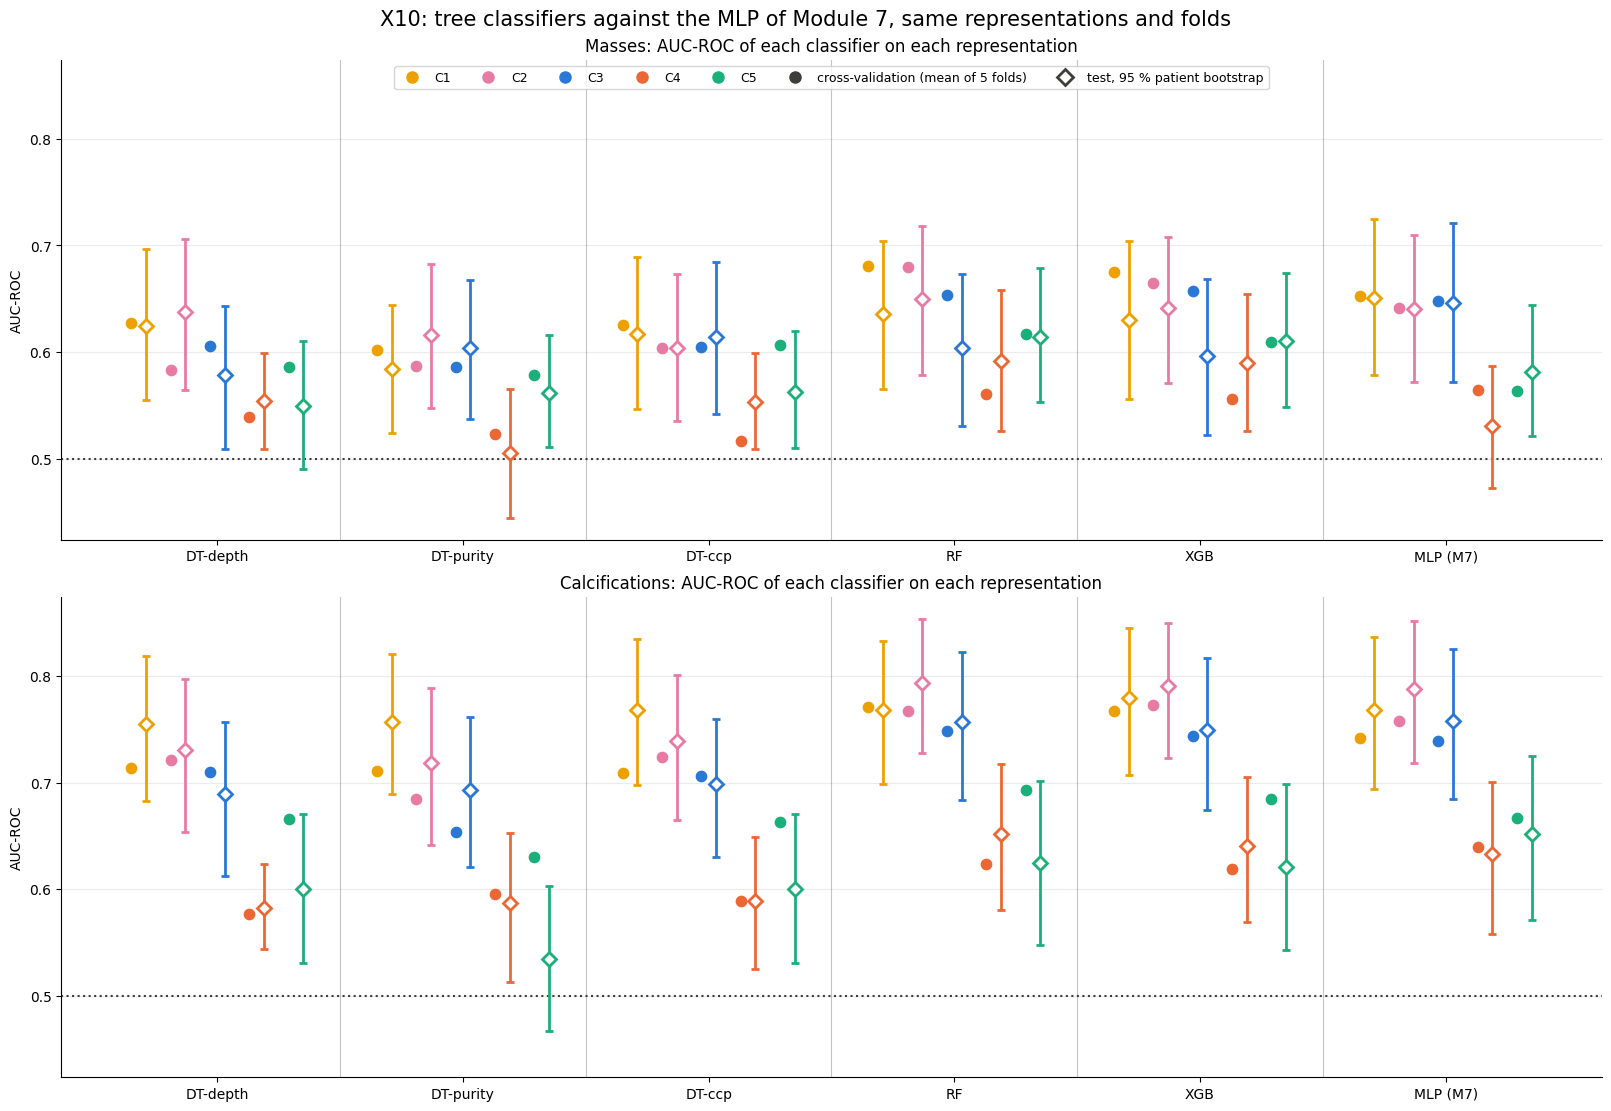

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(16, 11), constrained_layout=True, sharey=True)
offsets = np.linspace(-0.32, 0.32, len(CONDITIONS))
for ax, ft in zip(axes, FINDINGS):
    cvm = cv_all[cv_all.finding_type == ft].groupby(['family', 'condition']).auc.mean()
    tt = test_table[test_table.finding_type == ft].set_index(['family', 'condition'])
    for i, fam in enumerate(ALL_FAMILIES):
        for off, cond in zip(offsets, CONDITIONS):
            ax.scatter(i + off - 0.03, cvm[(fam, cond)], color=COLORS[cond], s=55, zorder=3)
            r = tt.loc[(fam, cond)]
            ax.errorbar(i + off + 0.03, r.auc, yerr=[[r.auc - r.auc_ci_low], [r.auc_ci_high - r.auc]], fmt='D', color=COLORS[cond],
                        markerfacecolor='white', markeredgewidth=2, markersize=7, capsize=3, zorder=3)
        if i:
            ax.axvline(i - 0.5, color=INK, lw=0.8, alpha=0.3)
    ax.axhline(0.5, color=INK, ls=':', lw=1.5)
    ax.set_xticks(range(len(ALL_FAMILIES)), ALL_FAMILIES)
    ax.grid(axis='x', visible=False)
    ax.set(title=f'{TITLES[ft]}: AUC-ROC of each classifier on each representation', ylabel='AUC-ROC')
handles = [Line2D([], [], marker='o', ls='', color=COLORS[c], label=c) for c in CONDITIONS] + \
          [Line2D([], [], marker='o', ls='', color=INK, label='cross-validation (mean of 5 folds)'),
           Line2D([], [], marker='D', ls='', color=INK, markerfacecolor='white', markeredgewidth=2, label='test, 95 % patient bootstrap')]
axes[0].legend(handles=handles, fontsize=9, loc='upper center', ncol=7)
fig.suptitle('X10: tree classifiers against the MLP of Module 7, same representations and folds', fontsize=15)
fig.savefig(FIG_DIR / 'X10_auc.png', dpi=180, bbox_inches='tight')
plt.show()

#### **4° Why the trees win or lose**

**a.** How deep should a tree be? Training and validation AUC against each stopping rule, averaged over the five outer folds. The training curve keeps rising as the tree grows; the validation curve rises, peaks and falls. The fall is overfitting: the tree starts memorizing the training lesions. The marker is the value chosen by the nested search for the final model.

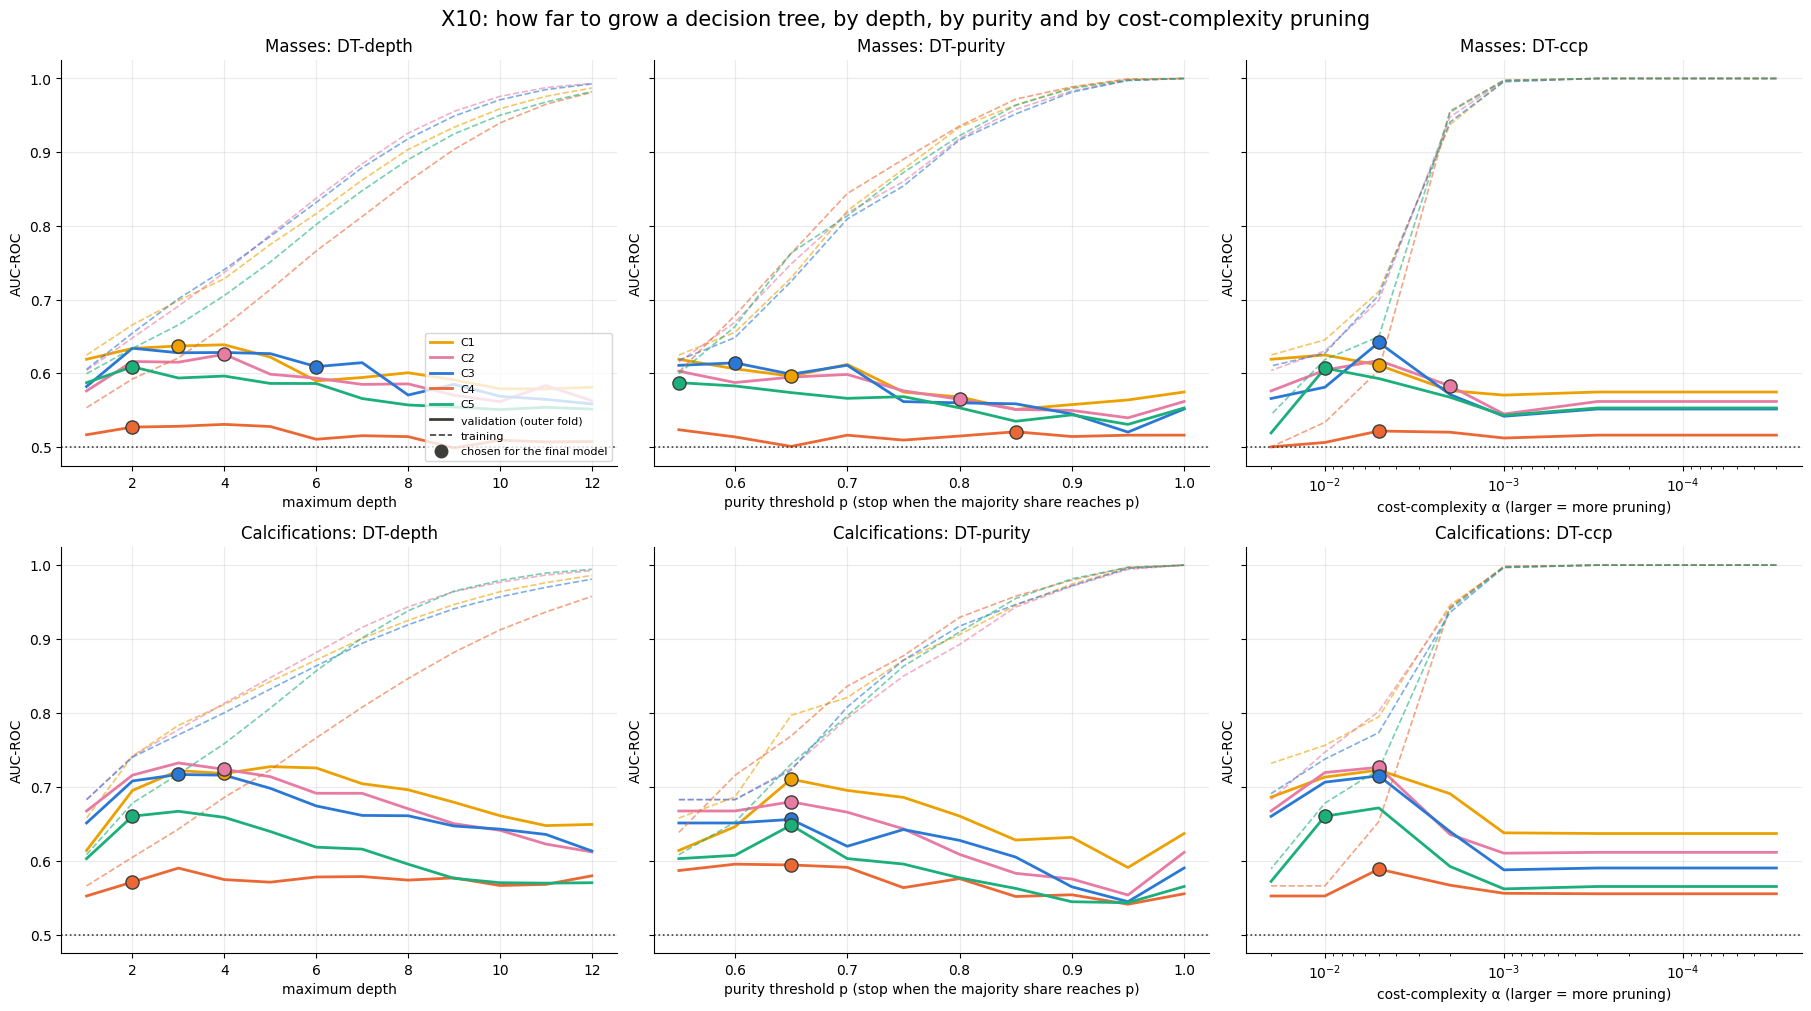

,finding_type,family,condition,value,train_auc,val_auc
5,calcification,DT-ccp,C1,0.005,0.795,0.723
13,calcification,DT-ccp,C2,0.005,0.802,0.726
21,calcification,DT-ccp,C3,0.005,0.773,0.715
29,calcification,DT-ccp,C4,0.005,0.653,0.589
37,calcification,DT-ccp,C5,0.005,0.723,0.671
44,calcification,DT-depth,C1,5.000,0.843,0.727
54,calcification,DT-depth,C2,3.000,0.777,0.732
66,calcification,DT-depth,C3,3.000,0.770,0.717
78,calcification,DT-depth,C4,3.000,0.643,0.590
90,calcification,DT-depth,C5,3.000,0.717,0.667


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True, sharey='row')
labels = {'DT-depth': 'maximum depth', 'DT-purity': 'purity threshold p (stop when the majority share reaches p)',
          'DT-ccp': 'cost-complexity α (larger = more pruning)'}
for row, ft in zip(axes, FINDINGS):
    for ax, fam in zip(row, STOP_PARAM):
        c = curves[(curves.finding_type == ft) & (curves.family == fam)].groupby(['condition', 'value'])[['train_auc', 'val_auc']].mean()
        for cond in CONDITIONS:
            cc = c.loc[cond]
            xs = cc.index.to_numpy(float)
            if fam == 'DT-ccp':
                xs = np.where(xs == 0, 3e-5, xs)
            ax.plot(xs, cc.val_auc, color=COLORS[cond], lw=2, label=f'{cond} validation')
            ax.plot(xs, cc.train_auc, color=COLORS[cond], lw=1.2, ls='--', alpha=0.6)
            chosen = finals[(ft, fam, cond)]['params'][STOP_PARAM[fam]]
            x_chosen = 3e-5 if fam == 'DT-ccp' and chosen == 0 else chosen      # alpha = 0 drawn at the left end of the log axis
            ax.scatter([x_chosen], [cc.val_auc.loc[chosen]], color=COLORS[cond], s=90, edgecolor=INK, zorder=4)
        if fam == 'DT-ccp':
            ax.set_xscale('log')
            ax.invert_xaxis()
        ax.axhline(0.5, color=INK, ls=':', lw=1.2)
        ax.set(title=f'{TITLES[ft]}: {fam}', xlabel=labels[fam], ylabel='AUC-ROC')
axes[0, 0].legend(handles=[Line2D([], [], color=COLORS[c], label=c) for c in CONDITIONS] +
                  [Line2D([], [], color=INK, lw=2, label='validation (outer fold)'),
                   Line2D([], [], color=INK, lw=1.2, ls='--', label='training'),
                   Line2D([], [], marker='o', ls='', color=INK, markersize=9, label='chosen for the final model')], fontsize=8, loc='lower right')
fig.suptitle('X10: how far to grow a decision tree, by depth, by purity and by cost-complexity pruning', fontsize=15)
fig.savefig(FIG_DIR / 'X10_stopping_curves.png', dpi=180, bbox_inches='tight')
plt.show()

stop_table = curves.groupby(['finding_type', 'family', 'condition', 'value'])[['train_auc', 'val_auc']].mean().reset_index()
peak = stop_table.loc[stop_table.groupby(['finding_type', 'family', 'condition']).val_auc.idxmax()]
display(peak.round(3))

**b.** Size of the final decision trees. A tree with $L$ leaves gives at most $L$ distinct probabilities, so its AUC is computed with many ties and comes out lower than that of a model with continuous scores. Part of the gap between a single tree and the forest is this granularity and not missing information. For the purity tree, the leaves are the distinct stopping nodes reached by the training lesions.

In [12]:
size_rows = []
for (ft, fam, cond), fin in finals.items():
    if fam not in STOP_PARAM:
        continue
    d = data[ft]
    if fam == 'DT-purity':
        leaves = len(np.unique(purity_scores(fin['model'], d['X'][cond][d['tr']], fin['params']['purity'])[1]))
        depth = fin['model'].get_depth()
    else:
        leaves, depth = fin['model'].get_n_leaves(), fin['model'].get_depth()
    size_rows.append({'finding_type': ft, 'family': fam, 'condition': cond, 'chosen': json.dumps(fin['params']),
                      'grown_depth': depth, 'leaves_used': leaves, 'distinct_test_scores': len(np.unique(fin['test']))})
sizes = pd.DataFrame(size_rows)
display(sizes)

,finding_type,family,condition,chosen,grown_depth,leaves_used,distinct_test_scores
0,mass,DT-depth,C1,"{""max_depth"": 3}",3,8,7
1,mass,DT-depth,C2,"{""max_depth"": 4}",4,15,14
2,mass,DT-depth,C3,"{""max_depth"": 6}",6,50,25
3,mass,DT-depth,C4,"{""max_depth"": 2}",2,4,4
4,mass,DT-depth,C5,"{""max_depth"": 2}",2,4,4
5,mass,DT-purity,C1,"{""purity"": 0.65}",23,20,16
6,mass,DT-purity,C2,"{""purity"": 0.8}",17,105,34
7,mass,DT-purity,C3,"{""purity"": 0.6}",19,4,4
8,mass,DT-purity,C4,"{""purity"": 0.85}",21,187,28
9,mass,DT-purity,C5,"{""purity"": 0.55}",23,2,2


**c.** Interactions or one-feature cuts? XGBoost with and without interactions, on cross-validation. The additive model fits a sum of one-feature functions; the full model can also combine features. **If they tie, the trees gain from non-linear cuts on each feature, not from interactions**; if the full model wins, interactions carry information. The interval is a patient bootstrap of the cross-validated AUC (resampling training patients, as in X6), paired between the two models.

,finding_type,condition,xgb_auc,additive_auc,full_minus_additive,ci_low,ci_high
0,mass,C1,0.675,0.657,0.018,0.007,0.029
1,mass,C2,0.665,0.652,0.012,-0.003,0.028
2,mass,C3,0.657,0.636,0.021,0.005,0.037
3,mass,C4,0.555,0.549,0.006,-0.009,0.022
4,mass,C5,0.610,0.603,0.006,-0.010,0.023
5,calcification,C1,0.768,0.762,0.006,-0.010,0.023
6,calcification,C2,0.773,0.768,0.004,-0.007,0.015
7,calcification,C3,0.744,0.748,-0.003,-0.013,0.007
8,calcification,C4,0.618,0.630,-0.011,-0.028,0.007
9,calcification,C5,0.685,0.640,0.045,0.023,0.065


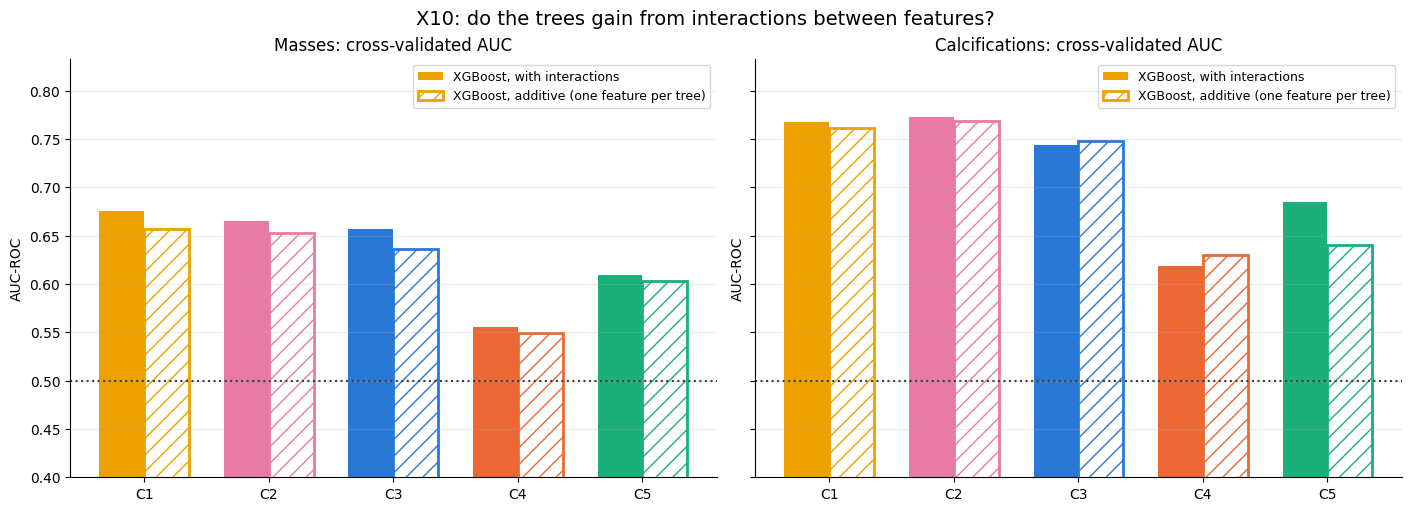

In [13]:
add_rows, boot_cv = [], {}
for ft in FINDINGS:
    d = data[ft]
    trn = np.flatnonzero(d['tr'])
    uniq, inv = np.unique(d['groups'][trn], return_inverse=True)
    members = [trn[inv == i] for i in range(len(uniq))]
    rng = np.random.default_rng(SEED)
    samples = [np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))]) for _ in range(N_BOOT)]
    cvp = preds[(preds.finding_type == ft) & (preds.split == 'cv')]
    for cond in CONDITIONS:
        dist = {}
        for fam in ['XGB', 'XGB-additive']:
            s_all = np.full(len(d['y']), np.nan)
            part = cvp[(cvp.family == fam) & (cvp.condition == cond)]
            s_all[trn] = part.prob.to_numpy()
            dist[fam] = np.array([np.mean([fast_auc(d['y'][s[d['folds'][s] == f]], s_all[s[d['folds'][s] == f]]) for f in range(N_FOLDS)])
                                  for s in samples])
        dd = dist['XGB'] - dist['XGB-additive']
        m = cv[(cv.finding_type == ft) & (cv.condition == cond)].groupby('family').auc.mean()
        add_rows.append({'finding_type': ft, 'condition': cond, 'xgb_auc': m['XGB'], 'additive_auc': m['XGB-additive'],
                         'full_minus_additive': m['XGB'] - m['XGB-additive'], 'ci_low': np.percentile(dd, 2.5),
                         'ci_high': np.percentile(dd, 97.5)})
additive = pd.DataFrame(add_rows)
display(additive.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True, sharey=True)
top = additive[['xgb_auc', 'additive_auc']].to_numpy().max() + 0.06
for ax, ft in zip(axes, FINDINGS):
    a = additive[additive.finding_type == ft].set_index('condition').loc[CONDITIONS]
    pos = np.arange(len(CONDITIONS))
    ax.bar(pos - 0.18, a.xgb_auc, 0.36, color=[COLORS[c] for c in CONDITIONS], label='XGBoost, with interactions')
    ax.bar(pos + 0.18, a.additive_auc, 0.36, color='white', edgecolor=[COLORS[c] for c in CONDITIONS], linewidth=2, hatch='//',
           label='XGBoost, additive (one feature per tree)')
    ax.axhline(0.5, color=INK, ls=':', lw=1.5)
    ax.set_ylim(0.4, top)
    ax.set_xticks(pos, CONDITIONS)
    ax.grid(axis='x', visible=False)
    ax.set(title=f'{TITLES[ft]}: cross-validated AUC', ylabel='AUC-ROC')
    ax.legend(fontsize=9, loc='upper right')
fig.suptitle('X10: do the trees gain from interactions between features?', fontsize=14)
fig.savefig(FIG_DIR / 'X10_additive.png', dpi=180, bbox_inches='tight')
plt.show()

**d.** Which inputs do the forest and the boosted trees use? Permutation importance on each outer validation fold: how much the AUC drops when one input is shuffled, averaged over the five folds. In C1 the inputs are the radiomic features of M4. In C4 and C5, input $i$ is $\langle Z_i\rangle$ after the fixed ansatz, which mixes the qubits, so it does not belong to feature $i$ alone. In C2 and C3 the inputs are components.

10:32:12 permutation importance done in 1.7 min


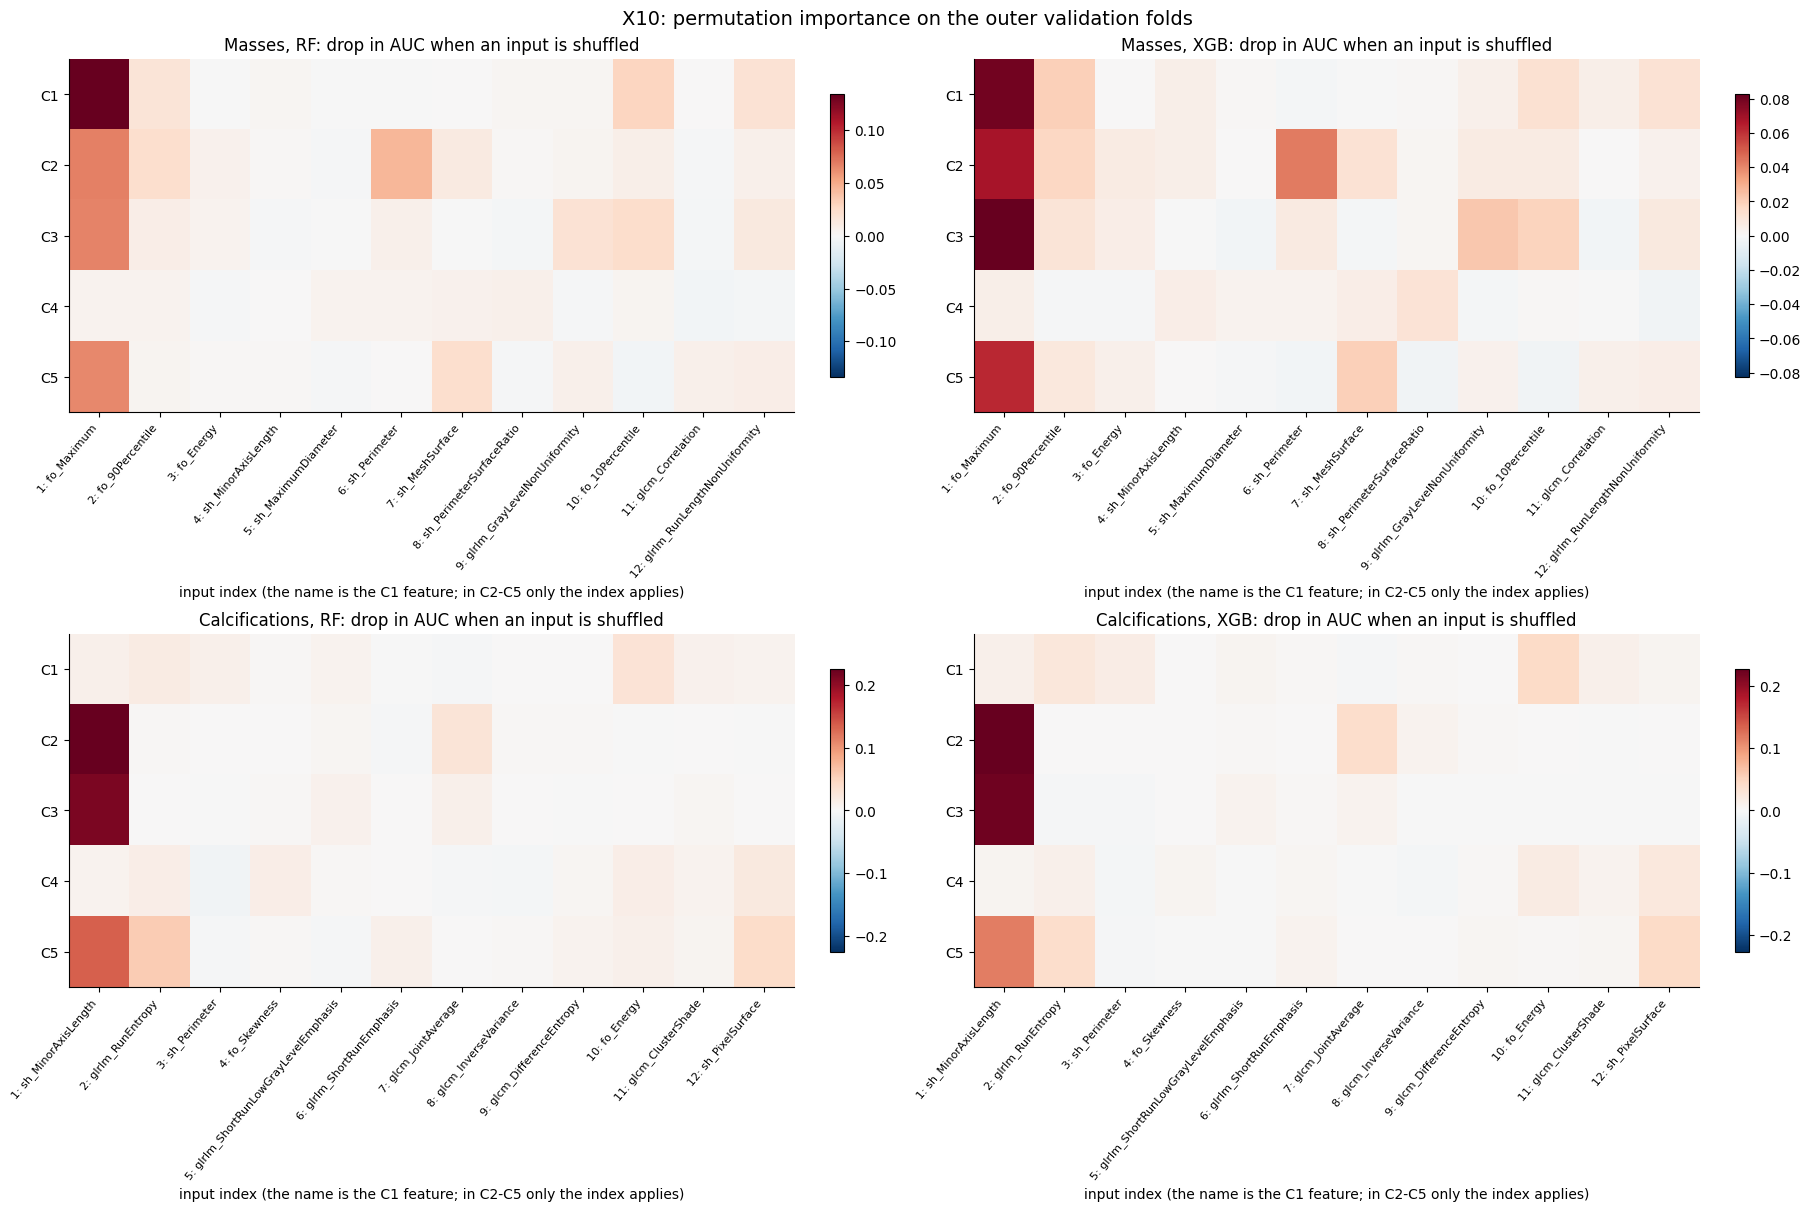

,finding_type,family,condition,input,feature,importance
9,calcification,RF,C1,10,fo_Energy,0.0301
1,calcification,RF,C1,2,glrlm_RunEntropy,0.0191
0,calcification,RF,C1,1,sh_MinorAxisLength,0.0117
2,calcification,RF,C1,3,sh_Perimeter,0.0116
69,calcification,XGB,C1,10,fo_Energy,0.0440
61,calcification,XGB,C1,2,glrlm_RunEntropy,0.0255
62,calcification,XGB,C1,3,sh_Perimeter,0.0165
70,calcification,XGB,C1,11,glcm_ClusterShade,0.0119
120,mass,RF,C1,1,fo_Maximum,0.1339
129,mass,RF,C1,10,fo_10Percentile,0.0283


In [14]:
imp_rows = []
t0 = time.perf_counter()
for ft in FINDINGS:
    d = data[ft]
    for fam in ['RF', 'XGB']:
        chosen = cv[(cv.finding_type == ft) & (cv.family == fam)].set_index(['condition', 'fold']).chosen
        for cond in CONDITIONS:
            X, y = d['X'][cond], d['y']
            for f in range(N_FOLDS):
                a, b = np.flatnonzero(d['tr'] & (d['folds'] != f)), np.flatnonzero(d['folds'] == f)
                m = fit(fam, json.loads(chosen[(cond, f)]), X[a], y[a])
                r = permutation_importance(m, X[b], y[b], scoring='roc_auc', n_repeats=N_PERM, random_state=SEED)
                for j in range(K):
                    imp_rows.append({'finding_type': ft, 'family': fam, 'condition': cond, 'fold': f, 'input': j + 1,
                                     'feature': d['features'][j] if cond == 'C1' else f'{cond}_{j + 1:02d}', 'importance': r.importances_mean[j]})
log(f'permutation importance done in {(time.perf_counter() - t0) / 60:.1f} min')
importance = pd.DataFrame(imp_rows).groupby(['finding_type', 'family', 'condition', 'input', 'feature']).importance.mean().reset_index()

fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)
for row, ft in zip(axes, FINDINGS):
    for ax, fam in zip(row, ['RF', 'XGB']):
        m = importance[(importance.finding_type == ft) & (importance.family == fam)].pivot(index='condition', columns='input', values='importance')
        lim = np.abs(m.to_numpy()).max()
        im = ax.imshow(m.to_numpy(), cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
        ax.set_yticks(range(len(m.index)), m.index)
        ax.set_xticks(range(K), [f'{j + 1}: {data[ft]["features"][j]}' for j in range(K)], fontsize=8, rotation=50, ha='right')
        ax.grid(False)
        ax.set(title=f'{TITLES[ft]}, {fam}: drop in AUC when an input is shuffled', xlabel='input index (the name is the C1 feature; in C2-C5 only the index applies)')
        fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('X10: permutation importance on the outer validation folds', fontsize=14)
fig.savefig(FIG_DIR / 'X10_importance.png', dpi=180, bbox_inches='tight')
plt.show()
display(importance[importance.condition == 'C1'].sort_values(['finding_type', 'family', 'importance'], ascending=[True, True, False])
        .groupby(['finding_type', 'family']).head(4).round(4))

**e.** A tree that can be read: depth 3 on C1, fitted on the whole training split. This is the only representation whose rules mean something to a radiologist. A rule such as "⟨Z₃⟩ < 0.02" in C4 has no clinical reading, so the interpretability of a tree only exists in C1.

In [15]:
rules = []
for ft in FINDINGS:
    d = data[ft]
    trn = d['tr']
    t3 = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED).fit(d['X']['C1'][trn], d['y'][trn])
    text = export_text(t3, feature_names=d['features'], show_weights=True, decimals=3)
    rules.append(f'=== {TITLES[ft]}: decision tree of depth 3 on C1 (angles in [0, pi] after the quantile scaling of M4; '
                 f'weights = class-weighted lesions [benign, malignant] in each leaf) ===\n{text}')
    print(rules[-1])
(RESULTS_DIR / 'X10_reglas_arbol_C1.txt').write_text('\n'.join(rules))

=== Masses: decision tree of depth 3 on C1 (angles in [0, pi] after the quantile scaling of M4; weights = class-weighted lesions [benign, malignant] in each leaf) ===
|--- fo_Maximum <= 1.209
|   |--- fo_10Percentile <= 1.075
|   |   |--- fo_Maximum <= 0.346
|   |   |   |--- weights: [101.608, 37.243] class: 0
|   |   |--- fo_Maximum >  0.346
|   |   |   |--- weights: [89.996, 90.005] class: 1
|   |--- fo_10Percentile >  1.075
|   |   |--- fo_90Percentile <= 0.795
|   |   |   |--- weights: [26.128, 1.035] class: 0
|   |   |--- fo_90Percentile >  0.795
|   |   |   |--- weights: [115.156, 41.381] class: 0
|--- fo_Maximum >  1.209
|   |--- fo_Energy <= 2.310
|   |   |--- fo_Maximum <= 3.085
|   |   |   |--- weights: [209.990, 249.323] class: 1
|   |   |--- fo_Maximum >  3.085
|   |   |   |--- weights: [13.548, 2.069] class: 0
|   |--- fo_Energy >  2.310
|   |   |--- fo_90Percentile <= 2.008
|   |   |   |--- weights: [36.772, 39.312] class: 1
|   |   |--- fo_90Percentile >  2.008
|   |   |

2108

#### **5° How many folds?**

**a.** The balance of the folds with 3 to 10 folds, with the rule of D-026: among 200 seeds of `StratifiedGroupKFold`, the one that minimizes the largest deviation of the malignant share between folds. It only looks at labels. With 5 folds it must reproduce seeds 125 and 168 of M4.

In [16]:
def group_folds(tr, k, seed):
    fold = np.empty(len(tr), int)
    for i, (_, va) in enumerate(StratifiedGroupKFold(k, shuffle=True, random_state=seed).split(tr, tr.label.values, tr.patient_id.values)):
        fold[va] = i
    return fold


def max_dev(y, fold):
    return float(np.abs(pd.Series(y).groupby(fold).mean() - y.mean()).max())


t0 = time.perf_counter()
bal_rows, folds3 = [], {}
for ft in FINDINGS:
    m4 = pd.read_parquet(M4_DIR / f'x_{ft}.parquet')
    trf = m4[m4.split == 'train'].reset_index(drop=True)              # the order M4 used to draw its folds
    y = trf.label.values
    biggest = trf.patient_id.value_counts().max()
    for k in [3, 4, 5, 6, 8, 10]:
        devs = pd.Series({s: max_dev(y, group_folds(trf, k, s)) for s in range(N_SEED_CANDIDATES)})
        best = int(devs[devs == devs.min()].index.min())
        f = group_folds(trf, k, best)
        fold_sizes, mal = pd.Series(f).value_counts(), pd.Series(y).groupby(f).sum()
        bal_rows.append({'finding_type': ft, 'k': k, 'train_share': (k - 1) / k, 'seed': best, 'max_dev_best': devs[best],
                         'max_dev_median': devs.median(), 'max_dev_worst': devs.max(), 'lesions_min': fold_sizes.min(), 'lesions_max': fold_sizes.max(),
                         'malignant_min': mal.min(), 'largest_patient_lesions': biggest, 'largest_patient_share': biggest / fold_sizes.min()})
        if k == 5 and not QUICK:
            check(f'{ft}: the D-026 rule reproduces the M4 folds with k = 5', best, (f == trf.fold.values).all())
        if k == 3:
            folds3[ft] = dict(zip(trf.case_id, f))
            split3 = int((pd.Series(f).groupby(trf.patient_id.values).nunique() > 1).sum())
            check(f'{ft}: no patient has lesions in two of the 3 folds', split3, split3 == 0)
balance = pd.DataFrame(bal_rows)
log(f'fold balance done in {time.perf_counter() - t0:.0f} s')
display(balance.round(3))

10:34:24 fold balance done in 131 s


,finding_type,k,train_share,seed,max_dev_best,max_dev_median,max_dev_worst,lesions_min,lesions_max,malignant_min,largest_patient_lesions,largest_patient_share
0,mass,3,0.667,68,0.003,0.033,0.108,414,465,200,14,0.034
1,mass,4,0.750,199,0.006,0.055,0.112,313,351,150,14,0.045
2,mass,5,0.800,125,0.011,0.060,0.137,255,280,122,14,0.055
3,mass,6,0.833,7,0.020,0.071,0.161,207,243,96,14,0.068
4,mass,8,0.875,183,0.035,0.094,0.164,145,182,65,14,0.097
5,mass,10,0.900,81,0.044,0.109,0.186,125,150,57,14,0.112
6,calcification,3,0.667,119,0.003,0.037,0.106,478,552,167,24,0.050
7,calcification,4,0.750,7,0.009,0.051,0.151,378,397,131,24,0.063
8,calcification,5,0.800,168,0.019,0.065,0.168,271,324,96,24,0.089
9,calcification,6,0.833,106,0.030,0.080,0.202,233,286,79,24,0.103


**b.** The same table as a figure. Raising $k$ lets each model train on more data (the share under each $k$), but:
- **A.** The class balance between folds degrades. The solid line is the seed chosen by the rule of D-026; the dashed line is what a typical seed gives.
- **B.** Each validation fold keeps fewer malignant lesions, so the AUC of each fold is noisier.
- **C.** One indivisible patient weighs more in a fold. In calcifications that patient has 24 lesions, all benign.

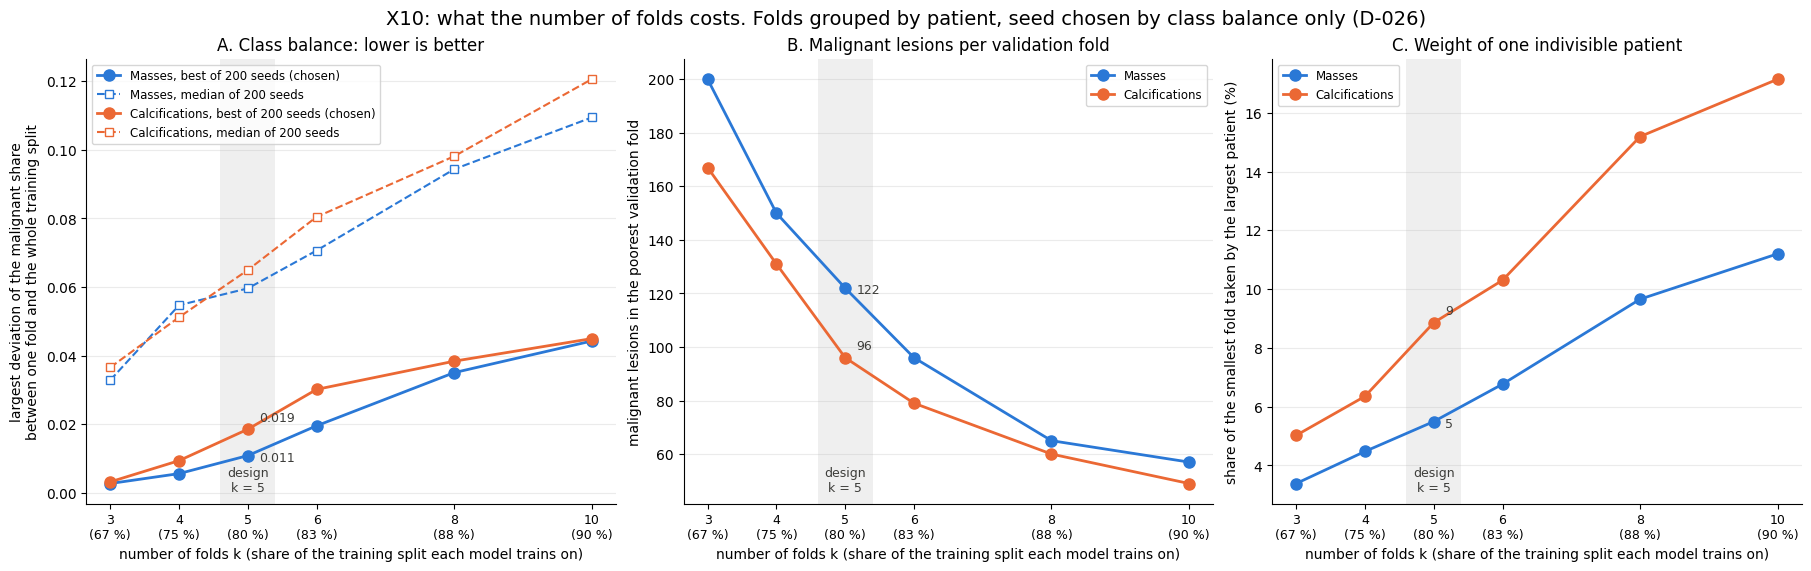

In [17]:
SUBSET_COLORS = {'mass': '#2a78d6', 'calcification': '#eb6834'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), constrained_layout=True, sharex=True)
ks = sorted(balance.k.unique())
panels = [('max_dev_best', 'max_dev_median', 'largest deviation of the malignant share\nbetween one fold and the whole training split',
           'A. Class balance: lower is better'),
          ('malignant_min', None, 'malignant lesions in the poorest validation fold', 'B. Malignant lesions per validation fold'),
          ('largest_patient_share', None, 'share of the smallest fold taken by the largest patient (%)',
           'C. Weight of one indivisible patient')]
for ax, (col, col2, ylabel, title) in zip(axes, panels):
    ax.axvspan(4.6, 5.4, color='#3d3d3a', alpha=0.08, lw=0)
    for ft in FINDINGS:
        b = balance[balance.finding_type == ft].sort_values('k')
        scale = 100 if col == 'largest_patient_share' else 1
        ax.plot(b.k, b[col] * scale, 'o-', color=SUBSET_COLORS[ft], label=f'{TITLES[ft]}' + (', best of 200 seeds (chosen)' if col2 else ''))
        if col2:
            ax.plot(b.k, b[col2], 's--', color=SUBSET_COLORS[ft], lw=1.5, markersize=6, markerfacecolor='white',
                    label=f'{TITLES[ft]}, median of 200 seeds')
        five = b[b.k == 5].iloc[0]
        ax.annotate(f'{five[col] * scale:.3f}' if col == 'max_dev_best' else f'{five[col] * scale:.0f}',
                    (5, five[col] * scale), textcoords='offset points', xytext=(8, -4 if ft == 'mass' else 6), fontsize=9, color=INK)
    ax.set(title=title, ylabel=ylabel, xlabel='number of folds k (share of the training split each model trains on)')
    ax.set_xticks(ks, [f'{k}\n({100 * (k - 1) / k:.0f} %)' for k in ks], fontsize=9)
    ax.text(5, 0.02, 'design\nk = 5', transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=9, color=INK)
    ax.grid(axis='x', visible=False)
    ax.legend(fontsize=8.5, loc='upper right' if col == 'malignant_min' else 'upper left')
fig.suptitle('X10: what the number of folds costs. Folds grouped by patient, seed chosen by class balance only (D-026)', fontsize=14)
fig.savefig(FIG_DIR / 'X10_balance_folds.png', dpi=180, bbox_inches='tight')
plt.show()

**c.** The MLP of Module 7 (D-036, seed 42) with 3 folds instead of 5, on cross-validation only. The code is copied from `7_Classification`, and its 5-fold run must reproduce `7_cv_por_fold.csv` before the 3-fold run is read.

10:34:28 mass: MLP with 5 and 3 folds done


10:34:34 calcification: MLP with 5 and 3 folds done


10:34:34 fold sensitivity done in 0.2 min


mean           std       
n_folds                      3      5      3      5
finding_type  condition                            
calcification C1         0.757  0.742  0.029  0.038
              C2         0.764  0.758  0.014  0.046
              C3         0.750  0.739  0.029  0.036
              C4         0.638  0.640  0.013  0.041
              C5         0.664  0.667  0.034  0.035
mass          C1         0.667  0.652  0.056  0.068
              C2         0.675  0.641  0.025  0.059
              C3         0.668  0.648  0.034  0.055
              C4         0.544  0.565  0.048  0.079
              C5         0.569  0.563  0.020  0.024

condition                 C1     C2     C3     C4     C5  C4 - C1  C5 - C1
finding_type  n_folds                                                     
calcification 3        0.757  0.764  0.750  0.638  0.664   -0.119   -0.092
              5        0.742  0.758  0.739  0.640  0.667   -0.102   -0.075
mass          3        0.667  0.675  0.668  0.544  0.569   -0.123   -0.098
              5        0.652  0.641  0.648  0.565  0.563   -0.087   -0.089

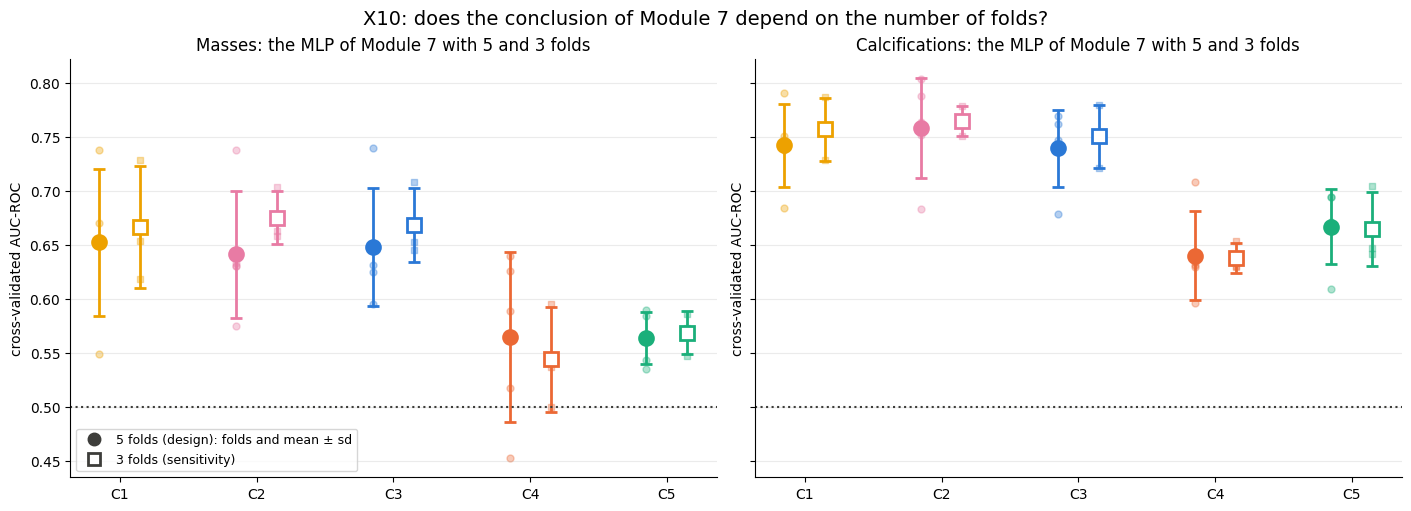

In [18]:
class MLP(torch.nn.Module):
    def __init__(self, n_in, hidden):
        super().__init__()
        layers, dd = [], n_in
        for h in hidden:
            layers += [torch.nn.Linear(dd, h), torch.nn.ReLU()]
            dd = h
        layers.append(torch.nn.Linear(dd, 1))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def mlp_fit_predict(x_fit, y_fit, groups, x_eval, config, seed):
    inner_tr, inner_va = next(GroupShuffleSplit(n_splits=1, test_size=INNER_VAL, random_state=seed).split(x_fit, y_fit, groups))
    scaler = StandardScaler().fit(x_fit[inner_tr]) if config['standardize'] else None
    prep = (lambda arr: torch.tensor(scaler.transform(arr) if scaler else arr, dtype=torch.float32))
    w = class_weights(y_fit[inner_tr])
    xt, yt = prep(x_fit[inner_tr]), torch.tensor(y_fit[inner_tr], dtype=torch.float32)
    wt = torch.where(yt == 1, w[1], w[0])
    xv, yv = prep(x_fit[inner_va]), torch.tensor(y_fit[inner_va], dtype=torch.float32)
    wv = torch.where(yv == 1, w[1], w[0])
    torch.manual_seed(seed)
    model = MLP(x_fit.shape[1], config['hidden'])
    opt = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    loss_fn = torch.nn.BCEWithLogitsLoss(reduction='none')
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_epoch, wait = np.inf, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(xt), generator=gen)
        for i in range(0, len(xt), BATCH):
            bb = order[i:i + BATCH]
            opt.zero_grad()
            (loss_fn(model(xt[bb]), yt[bb]) * wt[bb]).mean().backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = float((loss_fn(model(xv), yv) * wv).mean())
        if val < best - 1e-6:
            best, best_state, best_epoch, wait = val, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(prep(x_eval))).numpy(), best_epoch


torch.set_num_threads(1)
t0 = time.perf_counter()
fold_rows = []
for ft in FINDINGS:
    d = data[ft]
    trn = np.flatnonzero(d['tr'])
    y, g = d['y'][trn], d['groups'][trn]
    schemes = {5: d['folds'][trn], 3: d['frame'].case_id[trn].map(folds3[ft]).to_numpy(int)}
    for n_folds, fold in schemes.items():
        for cond in CONDITIONS:
            x = d['X'][cond][trn]
            for f in range(n_folds):
                fit_m, ev = fold != f, fold == f
                p, ep = mlp_fit_predict(x[fit_m], y[fit_m], g[fit_m], x[ev], MLP_CONFIG, SEED)
                fold_rows.append({'finding_type': ft, 'n_folds': n_folds, 'condition': cond, 'fold': f, 'epochs': ep,
                                  'train_lesions': int(fit_m.sum()), **metrics(y[ev], p)})
    log(f'{ft}: MLP with 5 and 3 folds done')
folds_mlp = pd.DataFrame(fold_rows)
log(f'fold sensitivity done in {(time.perf_counter() - t0) / 60:.1f} min')

ref = m7_cv.set_index(['finding_type', 'condition', 'fold']).auc
mine = folds_mlp[folds_mlp.n_folds == 5].set_index(['finding_type', 'condition', 'fold']).auc
err = np.abs(mine - ref.loc[mine.index]).max()
check('the 5-fold MLP replica reproduces the AUC of every fold of 7_cv_por_fold.csv', err, err < 1e-12)
fold_summary = folds_mlp.groupby(['finding_type', 'n_folds', 'condition']).auc.agg(['mean', 'std']).unstack('n_folds')
gap = folds_mlp.groupby(['finding_type', 'n_folds', 'condition']).auc.mean().unstack('condition')
gap['C4 - C1'], gap['C5 - C1'] = gap.C4 - gap.C1, gap.C5 - gap.C1
display(fold_summary.round(3))
display(gap.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True, sharey=True)
for ax, ft in zip(axes, FINDINGS):
    for j, (n_folds, marker) in enumerate([(5, 'o'), (3, 's')]):
        part = folds_mlp[(folds_mlp.finding_type == ft) & (folds_mlp.n_folds == n_folds)]
        for i, cond in enumerate(CONDITIONS):
            a = part[part.condition == cond].auc
            xpos = i + (j - 0.5) * 0.3
            ax.scatter(np.full(len(a), xpos), a, color=COLORS[cond], alpha=0.35, s=25, marker=marker)
            ax.errorbar(xpos, a.mean(), yerr=a.std(), fmt=marker, color=COLORS[cond], markersize=10, capsize=4,
                        markerfacecolor=COLORS[cond] if n_folds == 5 else 'white', markeredgewidth=2)
    ax.axhline(0.5, color=INK, ls=':', lw=1.5)
    ax.set_xticks(range(len(CONDITIONS)), CONDITIONS)
    ax.grid(axis='x', visible=False)
    ax.set(title=f'{TITLES[ft]}: the MLP of Module 7 with 5 and 3 folds', ylabel='cross-validated AUC-ROC')
axes[0].legend(handles=[Line2D([], [], marker='o', ls='', color=INK, markersize=9, label='5 folds (design): folds and mean ± sd'),
                        Line2D([], [], marker='s', ls='', color=INK, markerfacecolor='white', markeredgewidth=2, markersize=9,
                               label='3 folds (sensitivity)')], fontsize=9, loc='lower left')
fig.suptitle('X10: does the conclusion of Module 7 depend on the number of folds?', fontsize=14)
fig.savefig(FIG_DIR / 'X10_folds.png', dpi=180, bbox_inches='tight')
plt.show()

#### **6° Files and verifications**

In [19]:
n_test_models = preds[preds.split == 'test'].groupby(['finding_type', 'family', 'condition']).ngroups
check('one test model per subset, classifier and representation', n_test_models, n_test_models == len(FINDINGS) * len(FAMILIES) * len(CONDITIONS))
check('the additive XGB never touched the test split', 0, preds[(preds.family == 'XGB-additive') & (preds.split == 'test')].empty)
check('every prediction is a probability', 0, preds.prob.between(0, 1).all())
check('one size row per subset, decision tree and representation', len(sizes), len(sizes) == len(FINDINGS) * len(STOP_PARAM) * len(CONDITIONS))
check('every training lesion has one cross-validated prediction per model', 0,
      preds[preds.split == 'cv'].groupby(['finding_type', 'family', 'condition']).prob.apply(lambda s: s.notna().all()).all())

cv.to_csv(RESULTS_DIR / 'X10_cv_por_fold.csv', index=False)
cv_table.reset_index().to_csv(RESULTS_DIR / 'X10_cv_resumen.csv', index=False)
test_table.to_csv(RESULTS_DIR / 'X10_test.csv', index=False)
diff.to_csv(RESULTS_DIR / 'X10_test_diferencias.csv', index=False)
stop_table.to_csv(RESULTS_DIR / 'X10_curvas_parada.csv', index=False)
sizes.to_csv(RESULTS_DIR / 'X10_tamano_arboles.csv', index=False)
additive.to_csv(RESULTS_DIR / 'X10_aditivo.csv', index=False)
importance.to_csv(RESULTS_DIR / 'X10_importancia.csv', index=False)
balance.to_csv(RESULTS_DIR / 'X10_balance_folds.csv', index=False)
folds_mlp.to_csv(RESULTS_DIR / 'X10_folds_mlp.csv', index=False)
ctrl.reset_index().to_csv(RESULTS_DIR / 'X10_control_positivo.csv', index=False)
preds.to_parquet(OUT_DIR / 'predicciones.parquet', index=False)
verifications = pd.DataFrame(checks)
verifications.to_csv(RESULTS_DIR / 'X10_verificaciones.csv', index=False)
display(verifications)
log(f'Checks passed: {int(verifications.passed.sum())}/{len(verifications)}')

,check,value,passed
0,mass: Module 5 folds equal the frozen folds of M4,0.000000e+00,True
1,mass: C1 is the angle vector of M4,0.000000e+00,True
2,mass: no patient has lesions in two folds,0.000000e+00,True
3,calcification: Module 5 folds equal the frozen...,0.000000e+00,True
4,calcification: C1 is the angle vector of M4,0.000000e+00,True
5,calcification: no patient has lesions in two f...,0.000000e+00,True
6,mass: no patient on both sides of an inner split,0.000000e+00,True
7,mass: the outer validation fold never enters i...,0.000000e+00,True
8,mass: the test split never enters any search,0.000000e+00,True
9,calcification: no patient on both sides of an ...,0.000000e+00,True


10:34:34 Checks passed: 30/30


In [20]:
print('=' * 100)
print('X10 - TREE CLASSIFIERS AND THE NUMBER OF FOLDS - SUMMARY (AUC-ROC)')
print('=' * 100)
for ft in FINDINGS:
    print(f'  {TITLES[ft]}')
    cvm = cv_all[cv_all.finding_type == ft].groupby(['family', 'condition']).auc.mean()
    tt = test_table[test_table.finding_type == ft].set_index(['family', 'condition'])
    for fam in ALL_FAMILIES:
        print(f'    {fam:10s} CV   ' + ' | '.join(f'{c} {cvm[(fam, c)]:.3f}' for c in CONDITIONS))
        print(f'    {"":10s} test ' + ' | '.join(f"{c} {tt.loc[(fam, c), 'auc']:.3f}" for c in CONDITIONS))
    sig = diff[(diff.finding_type == ft) & (diff.group == 'same classifier') & diff.second.str.endswith('C1')
               & diff['first'].str.contains('C4|C5') & (diff.ci_low > 0)]
    print(f'    quantum representation significantly above C1 with the same classifier: {len(sig)} of {2 * len(ALL_FAMILIES)}')
    a = additive[additive.finding_type == ft].set_index('condition')
    print('    XGB full - additive (CV): ' + ' | '.join(f"{c} {a.loc[c, 'full_minus_additive']:+.3f}" for c in CONDITIONS))
    g = gap.loc[ft]
    print('    MLP, C4 - C1 and C5 - C1 (CV): 5 folds ' + f"{g.loc[5, 'C4 - C1']:+.3f} {g.loc[5, 'C5 - C1']:+.3f}"
          f" | 3 folds {g.loc[3, 'C4 - C1']:+.3f} {g.loc[3, 'C5 - C1']:+.3f}")
print(f"  Checks passed: {int(verifications.passed.sum())}/{len(verifications)}")
print('=' * 100)

X10 - TREE CLASSIFIERS AND THE NUMBER OF FOLDS - SUMMARY (AUC-ROC)
  Masses
    DT-depth   CV   C1 0.627 | C2 0.583 | C3 0.606 | C4 0.539 | C5 0.586
               test C1 0.624 | C2 0.637 | C3 0.578 | C4 0.554 | C5 0.549
    DT-purity  CV   C1 0.602 | C2 0.586 | C3 0.586 | C4 0.523 | C5 0.579
               test C1 0.584 | C2 0.616 | C3 0.604 | C4 0.505 | C5 0.561
    DT-ccp     CV   C1 0.625 | C2 0.603 | C3 0.605 | C4 0.516 | C5 0.607
               test C1 0.617 | C2 0.603 | C3 0.614 | C4 0.553 | C5 0.563
    RF         CV   C1 0.681 | C2 0.680 | C3 0.654 | C4 0.561 | C5 0.617
               test C1 0.636 | C2 0.650 | C3 0.604 | C4 0.591 | C5 0.614
    XGB        CV   C1 0.675 | C2 0.665 | C3 0.657 | C4 0.555 | C5 0.610
               test C1 0.630 | C2 0.641 | C3 0.596 | C4 0.590 | C5 0.611
    MLP (M7)   CV   C1 0.652 | C2 0.641 | C3 0.648 | C4 0.565 | C5 0.563
               test C1 0.651 | C2 0.641 | C3 0.646 | C4 0.530 | C5 0.581
    quantum representation significantly above C

#### **7° Consequence**

*To be written after the results are reviewed (H-056).*